# Ensemble Technique 2: Rank Averaging

**Primary goal: MAXIMIZE TEST ACCURACY**

Rank Averaging converts each model's raw probabilities into normalized percentile ranks, then averages the ranks. This removes scale bias (e.g., EfficientNet outputting 0.9 vs ConvNeXt outputting 0.6 for the same image). Tests 11 variants including uniform, AUC-weighted, accuracy-weighted, geometric mean, and subset combinations. Threshold is optimized for accuracy, not fixed at 0.5.

In [1]:
# ── Cell 1: Imports ─────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                              classification_report, confusion_matrix)
print('Imports complete')


Imports complete


In [2]:
# ── Cell 2: Paths & Model Registry ────────────────────────────────────────
# Directory where all base-model .npy files were saved
NPY_DIR = '/kaggle/input/notebooks/nandini143/'

# Registry: maps a short model name → (val_probs_file, val_labels_file, test_probs_file)
MODEL_FILES = {
    'densenet121': (
        'binary-densenet-121/densenet121_val_probs.npy',
        'binary-densenet-121/densenet121_val_labels.npy',
        'binary-densenet-121/densenet121_test_probs.npy',
        'binary-densenet-121/densenet121_test_labels.npy',
    ),
    'convnext': (
        'binary-convnext/convnext_val_probs.npy',
        'binary-convnext/convnext_val_labels.npy',
        'binary-convnext/convnext_test_probs.npy',
        'binary-convnext/convnext_test_labels.npy',
    ),
    'efficientnetv2s': (
        'binary-efficientnetv2s/efficientnetv2s_val_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_val_labels.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_probs.npy',
        'binary-efficientnetv2s/efficientnetv2s_test_labels.npy',
    ),
    'swintiny': (
        'binary-swin-tiny-transformer/swintiny_val_probs.npy',
        'binary-swin-tiny-transformer/swintiny_val_labels.npy',
        'binary-swin-tiny-transformer/swintiny_test_probs.npy',
        'binary-swin-tiny-transformer/swintiny_test_labels.npy',
    ),
}
print('NPY_DIR:', NPY_DIR)

NPY_DIR: /kaggle/input/notebooks/nandini143/


In [3]:
# ── Cell 3: Load Predictions ────────────────────────────────────────────────
val_probs_dict   = {}
val_labels_dict  = {}
test_probs_dict  = {}
test_labels_dict = {}
val_aucs         = {}
val_accs         = {}
skipped_models   = []

print('Loading predictions')
print('-' * 70)

for model_name, (vp_f, vl_f, tp_f, tl_f) in MODEL_FILES.items():
    paths = {k: os.path.join(NPY_DIR, f) for k, f in zip(
        ['vp', 'vl', 'tp', 'tl'], [vp_f, vl_f, tp_f, tl_f])}
    missing = [k for k, v in paths.items() if not os.path.exists(v)]
    if missing:
        print(f'  [SKIP-MISSING]  {model_name:20s} -- missing: {missing}')
        skipped_models.append(model_name)
        continue

    vp = np.load(paths['vp'])
    vl = np.load(paths['vl']).astype(int)
    tp = np.load(paths['tp'])
    tl = np.load(paths['tl']).astype(int)

    if len(vp) != len(vl):
        print(f'  [SKIP-MISMATCH] {model_name:20s} -- val_probs={len(vp)} val_labels={len(vl)}')
        skipped_models.append(model_name)
        continue

    val_probs_dict[model_name]   = vp
    val_labels_dict[model_name]  = vl
    test_probs_dict[model_name]  = tp
    test_labels_dict[model_name] = tl

    auc  = roc_auc_score(vl, vp)
    acc  = accuracy_score(vl, (vp >= 0.5).astype(int))
    val_aucs[model_name] = auc
    val_accs[model_name] = acc
    print(f'  [OK] {model_name:20s}  val_AUC={auc:.4f}  val_ACC={acc*100:.2f}%  '
          f'n_val={len(vp)}  n_test={len(tp)}')

model_names = list(val_probs_dict.keys())
if len(model_names) == 0:
    raise RuntimeError('No models loaded.')

y_val  = val_labels_dict[model_names[0]]
y_test = test_labels_dict[model_names[0]]

print(f'\nLoaded {len(model_names)} models.')
print(f'y_val  size={len(y_val)}  malignant={y_val.sum()} ({y_val.mean()*100:.1f}%)')
print(f'y_test size={len(y_test)}  malignant={y_test.sum()} ({y_test.mean()*100:.1f}%)')


Loading predictions
----------------------------------------------------------------------
  [OK] densenet121           val_AUC=0.9479  val_ACC=87.29%  n_val=2533  n_test=2534
  [OK] convnext              val_AUC=0.9623  val_ACC=90.84%  n_val=2533  n_test=2534
  [OK] efficientnetv2s       val_AUC=0.9698  val_ACC=92.30%  n_val=2533  n_test=2534
  [OK] swintiny              val_AUC=0.9596  val_ACC=89.22%  n_val=2533  n_test=2534

Loaded 4 models.
y_val  size=2533  malignant=934 (36.9%)
y_test size=2534  malignant=934 (36.9%)


In [4]:
# ── Cell 4: Rank Conversion Helper ──────────────────────────────────────────
#
# rank_normalize(probs) converts raw probabilities to percentile ranks in [0, 1].
# Example: [0.1, 0.9, 0.5] -> [0.0, 1.0, 0.5]  (0=most benign, 1=most malignant)
#
# This eliminates scale differences between models.

def rank_normalize(probs):
    """Convert probs array to 0-1 normalized ranks (ties averaged)."""
    r = rankdata(probs, method='average')   # 1-based ranks
    return (r - 1) / (len(r) - 1)          # scale to [0, 1]

def best_threshold(y_true, probs, lo=0.25, hi=0.75, steps=200):
    """Find threshold that maximizes accuracy on y_true."""   
    thresholds = np.linspace(lo, hi, steps)
    accs = [accuracy_score(y_true, (probs >= t).astype(int)) for t in thresholds]
    best_t = thresholds[int(np.argmax(accs))]
    return best_t, max(accs)

results = {}

def evaluate(name, val_blend, test_blend):
    """Evaluate a blended prediction. Threshold optimized on val, applied to test."""   
    t, val_acc = best_threshold(y_val, val_blend)
    test_preds = (test_blend >= t).astype(int)
    test_acc   = accuracy_score(y_test, test_preds)
    test_auc   = roc_auc_score(y_test, test_blend)
    results[name] = dict(
        val_acc=val_acc, test_acc=test_acc, test_auc=test_auc,
        threshold=t, test_preds=test_preds, test_blend=test_blend
    )
    print(f'  {name:42s}  thr={t:.2f}  '
          f'val_ACC={val_acc*100:.2f}%  test_ACC={test_acc*100:.2f}%  '
          f'test_AUC={test_auc:.4f}')

print('Helpers ready.')
print()
print('KEY CONCEPT:')
print('  Raw prob averaging: avg(0.9_effnet, 0.6_convnext) = 0.75 (biased to EfficientNet scale)')
print('  Rank averaging:     avg(rank_0.99, rank_0.88)      = rank_0.935 (scale-neutral)')


Helpers ready.

KEY CONCEPT:
  Raw prob averaging: avg(0.9_effnet, 0.6_convnext) = 0.75 (biased to EfficientNet scale)
  Rank averaging:     avg(rank_0.99, rank_0.88)      = rank_0.935 (scale-neutral)


In [5]:
# ── Cell 5: Individual Model Baselines (Raw Probs, threshold-optimized) ─────
print('Individual baselines (raw probs, threshold-optimized):')
print('-' * 85)
for m in model_names:
    evaluate(f'Individual: {m}', val_probs_dict[m], test_probs_dict[m])


Individual baselines (raw probs, threshold-optimized):
-------------------------------------------------------------------------------------
  Individual: densenet121                     thr=0.43  val_ACC=88.47%  test_ACC=88.24%  test_AUC=0.9461
  Individual: convnext                        thr=0.49  val_ACC=90.96%  test_ACC=90.37%  test_AUC=0.9616
  Individual: efficientnetv2s                 thr=0.42  val_ACC=92.38%  test_ACC=91.16%  test_AUC=0.9657
  Individual: swintiny                        thr=0.35  val_ACC=90.88%  test_ACC=90.09%  test_AUC=0.9599


In [6]:
# ── Cell 6: Raw Probability Averaging ───────────────────────────────────────
print('\nRaw probability averaging:')
print('-' * 85)

# Uniform
val_raw_uniform  = np.mean([val_probs_dict[m]  for m in model_names], axis=0)
test_raw_uniform = np.mean([test_probs_dict[m] for m in model_names], axis=0)
evaluate('Raw Prob: Uniform Average', val_raw_uniform, test_raw_uniform)

# AUC-weighted
total_auc = sum(val_aucs.values())
val_raw_auc  = sum(val_aucs[m] / total_auc * val_probs_dict[m]  for m in model_names)
test_raw_auc = sum(val_aucs[m] / total_auc * test_probs_dict[m] for m in model_names)
evaluate('Raw Prob: AUC-Weighted Average', val_raw_auc, test_raw_auc)

# Accuracy-weighted (weight by val accuracy instead of AUC)
total_acc = sum(val_accs.values())
val_raw_acc_w  = sum(val_accs[m] / total_acc * val_probs_dict[m]  for m in model_names)
test_raw_acc_w = sum(val_accs[m] / total_acc * test_probs_dict[m] for m in model_names)
evaluate('Raw Prob: Accuracy-Weighted', val_raw_acc_w, test_raw_acc_w)



Raw probability averaging:
-------------------------------------------------------------------------------------
  Raw Prob: Uniform Average                   thr=0.41  val_ACC=92.62%  test_ACC=91.91%  test_AUC=0.9715
  Raw Prob: AUC-Weighted Average              thr=0.41  val_ACC=92.62%  test_ACC=91.91%  test_AUC=0.9715
  Raw Prob: Accuracy-Weighted                 thr=0.41  val_ACC=92.58%  test_ACC=91.87%  test_AUC=0.9716


In [7]:
# ── Cell 7: Rank Averaging ───────────────────────────────────────────────────
print('\nRank averaging (MAIN TECHNIQUE):')
print('-' * 85)

# Convert all probs to normalized ranks
val_ranks  = {m: rank_normalize(val_probs_dict[m])  for m in model_names}
test_ranks = {m: rank_normalize(test_probs_dict[m]) for m in model_names}

# 1. Uniform rank average
val_rank_uniform  = np.mean([val_ranks[m]  for m in model_names], axis=0)
test_rank_uniform = np.mean([test_ranks[m] for m in model_names], axis=0)
evaluate('Rank: Uniform Average', val_rank_uniform, test_rank_uniform)

# 2. AUC-weighted rank average
val_rank_auc  = sum(val_aucs[m] / total_auc * val_ranks[m]  for m in model_names)
test_rank_auc = sum(val_aucs[m] / total_auc * test_ranks[m] for m in model_names)
evaluate('Rank: AUC-Weighted', val_rank_auc, test_rank_auc)

# 3. Accuracy-weighted rank average
val_rank_acc  = sum(val_accs[m] / total_acc * val_ranks[m]  for m in model_names)
test_rank_acc = sum(val_accs[m] / total_acc * test_ranks[m] for m in model_names)
evaluate('Rank: Accuracy-Weighted', val_rank_acc, test_rank_acc)

# 4. Squared-AUC weighted (trust stronger models even more)
sq_aucs = {m: val_aucs[m]**2 for m in model_names}
total_sq_auc = sum(sq_aucs.values())
val_rank_sq_auc  = sum(sq_aucs[m] / total_sq_auc * val_ranks[m]  for m in model_names)
test_rank_sq_auc = sum(sq_aucs[m] / total_sq_auc * test_ranks[m] for m in model_names)
evaluate('Rank: Squared-AUC Weighted', val_rank_sq_auc, test_rank_sq_auc)

# 5. Best-2 rank average (exclude the 2 weakest models)
sorted_by_auc = sorted(model_names, key=lambda m: val_aucs[m], reverse=True)
top2 = sorted_by_auc[:2]
val_rank_top2  = np.mean([val_ranks[m]  for m in top2], axis=0)
test_rank_top2 = np.mean([test_ranks[m] for m in top2], axis=0)
evaluate(f'Rank: Top-2 Only ({top2[0]}, {top2[1]})', val_rank_top2, test_rank_top2)

# 6. Best-3 rank average (exclude weakest model)
top3 = sorted_by_auc[:3]
val_rank_top3  = np.mean([val_ranks[m]  for m in top3], axis=0)
test_rank_top3 = np.mean([test_ranks[m] for m in top3], axis=0)
evaluate(f'Rank: Top-3 Only (excl. {sorted_by_auc[-1]})', val_rank_top3, test_rank_top3)



Rank averaging (MAIN TECHNIQUE):
-------------------------------------------------------------------------------------
  Rank: Uniform Average                       thr=0.63  val_ACC=92.50%  test_ACC=91.63%  test_AUC=0.9701
  Rank: AUC-Weighted                          thr=0.63  val_ACC=92.50%  test_ACC=91.63%  test_AUC=0.9702
  Rank: Accuracy-Weighted                     thr=0.63  val_ACC=92.54%  test_ACC=91.67%  test_AUC=0.9703
  Rank: Squared-AUC Weighted                  thr=0.63  val_ACC=92.54%  test_ACC=91.67%  test_AUC=0.9702
  Rank: Top-2 Only (efficientnetv2s, convnext)  thr=0.64  val_ACC=92.81%  test_ACC=92.15%  test_AUC=0.9710
  Rank: Top-3 Only (excl. densenet121)        thr=0.62  val_ACC=92.81%  test_ACC=91.91%  test_AUC=0.9716


In [8]:
# -- Cell META: Rank + Metadata LR Meta-Learner --
# Uses per-model normalised ranks + 11 clinical metadata features.
# The meta-LR learns which model to trust for each patient subgroup.

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown',
]

_csv_dir  = '/kaggle/input/notebooks/nandini143/data-preparation'
_val_csv  = os.path.join(_csv_dir, 'binary_val.csv')
_test_csv = os.path.join(_csv_dir, 'binary_test.csv')

meta_rank_lr_val  = None
meta_rank_lr_test = None

if os.path.exists(_val_csv) and os.path.exists(_test_csv):
    _vdf = pd.read_csv(_val_csv)
    _tdf = pd.read_csv(_test_csv)
    _vcols = [c for c in METADATA_COLS if c in _vdf.columns]
    if _vcols:
        _mval  = _vdf[_vcols].fillna(0).values.astype('float32')
        _mtest = _tdf[_vcols].fillna(0).values.astype('float32')
        # val_ranks / test_ranks already built in Cell 7
        _vr = np.column_stack([val_ranks[m]  for m in model_names])
        _tr = np.column_stack([test_ranks[m] for m in model_names])
        if len(_mval) == len(_vr) and len(_mtest) == len(_tr):
            X_vm = np.hstack([_vr, _mval])
            X_tm = np.hstack([_tr, _mtest])
            meta_rank_lr = LogisticRegression(C=0.1, max_iter=1000, solver='lbfgs', random_state=42)
            meta_rank_lr.fit(X_vm, y_val)
            meta_rank_lr_val  = meta_rank_lr.predict_proba(X_vm)[:, 1]
            meta_rank_lr_test = meta_rank_lr.predict_proba(X_tm)[:, 1]
            _auc = roc_auc_score(y_val, meta_rank_lr_val)
            _acc = accuracy_score(y_val, (meta_rank_lr_val >= 0.5).astype(int))
            print('=' * 60)
            print('  [META] Rank + Metadata LR Meta-Learner')
            print(f'  Features : {len(model_names)} normalised ranks + {len(_vcols)} metadata cols')
            print(f'  Val AUC  : {_auc:.4f}')
            print(f'  Val ACC  : {_acc*100:.2f}%')
            print('=' * 60)
            print('  Rank feature coefficients:')
            for nm, c in zip(model_names, meta_rank_lr.coef_[0][:len(model_names)]):
                print(f'    {nm:20s}  coef = {c:+.4f}')
            print('  Metadata coefficients:')
            for nm, c in zip(_vcols, meta_rank_lr.coef_[0][len(model_names):]):
                print(f'    {nm:25s}  coef = {c:+.4f}')
            # Register result if evaluate() is available
            try:
                evaluate('Rank + Metadata LR', meta_rank_lr_val, meta_rank_lr_test)
            except Exception:
                pass
        else:
            print('[META] WARNING: row count mismatch.')
    else:
        print('[META] No metadata columns found in CSV.')
else:
    print(f'[META] CSVs not found at {_csv_dir}. Skipping rank-metadata LR.')

  [META] Rank + Metadata LR Meta-Learner
  Features : 4 normalised ranks + 11 metadata cols
  Val AUC  : 0.9738
  Val ACC  : 91.95%
  Rank feature coefficients:
    densenet121           coef = +1.8345
    convnext              coef = +2.4061
    efficientnetv2s       coef = +3.0172
    swintiny              coef = +2.2691
  Metadata coefficients:
    age_norm                   coef = +0.8757
    sex_encoded                coef = -0.0971
    site_anterior_torso        coef = +0.0332
    site_posterior_torso       coef = -0.0814
    site_head_neck             coef = +0.0759
    site_upper_extremity       coef = -0.0332
    site_lower_extremity       coef = -0.1395
    site_palms_soles           coef = +0.2089
    site_oral_genital          coef = -0.0856
    site_lateral_torso         coef = +0.0545
    site_unknown               coef = -0.0469
  Rank + Metadata LR                          thr=0.56  val_ACC=92.30%  test_ACC=91.48%  test_AUC=0.9704


In [9]:
# ── Cell 8: Power Averaging (Geometric & Harmonic Mean) ─────────────────────
print('\nPower averaging:')
print('-' * 85)

eps = 1e-7  # avoid log(0)

# Geometric mean (sqrt of products) -- penalizes models that disagree strongly
val_geo  = np.exp(np.mean([np.log(val_probs_dict[m]  + eps) for m in model_names], axis=0))
test_geo = np.exp(np.mean([np.log(test_probs_dict[m] + eps) for m in model_names], axis=0))
evaluate('Power: Geometric Mean (raw)', val_geo, test_geo)

# Geometric mean on ranks (more stable)
val_geo_rank  = np.exp(np.mean([np.log(val_ranks[m]  + eps) for m in model_names], axis=0))
test_geo_rank = np.exp(np.mean([np.log(test_ranks[m] + eps) for m in model_names], axis=0))
evaluate('Power: Geometric Mean (ranks)', val_geo_rank, test_geo_rank)

# Squared prob average (amplify high-confidence predictions)
val_sq  = np.mean([val_probs_dict[m]**2  for m in model_names], axis=0)
test_sq = np.mean([test_probs_dict[m]**2 for m in model_names], axis=0)
evaluate('Power: Squared Prob Average', val_sq, test_sq)



Power averaging:
-------------------------------------------------------------------------------------
  Power: Geometric Mean (raw)                 thr=0.41  val_ACC=92.74%  test_ACC=92.03%  test_AUC=0.9711
  Power: Geometric Mean (ranks)               thr=0.62  val_ACC=92.42%  test_ACC=91.75%  test_AUC=0.9694
  Power: Squared Prob Average                 thr=0.25  val_ACC=92.03%  test_ACC=91.55%  test_AUC=0.9714


In [10]:
# ── Cell 9: Full Comparison — Ranked by TEST ACCURACY ──────────────────────
print()
print('=' * 80)
print(f'  {"Rank":<5} {"Method":<44} {"Val Acc":>9} {"Test Acc":>10} {"AUC":>8}')
print('=' * 80)

sorted_results = sorted(results.items(), key=lambda x: x[1]['test_acc'], reverse=True)

for rank, (name, r) in enumerate(sorted_results, 1):
    marker = '  ** BEST **' if rank == 1 else ''
    print(f'  {rank:<5} {name:<44} {r["val_acc"]*100:>8.2f}%  '
          f'{r["test_acc"]*100:>9.2f}%  {r["test_auc"]:>8.4f}{marker}')

print('=' * 80)
best_name, best_r = sorted_results[0]
print(f'\nWINNER: {best_name}')
print(f'  Val  Accuracy : {best_r["val_acc"]*100:.2f}%')
print(f'  Test Accuracy : {best_r["test_acc"]*100:.2f}%')
print(f'  Test AUC      : {best_r["test_auc"]:.4f}')
print(f'  Threshold     : {best_r["threshold"]:.2f}')



  Rank  Method                                         Val Acc   Test Acc      AUC
  1     Rank: Top-2 Only (efficientnetv2s, convnext)    92.81%      92.15%    0.9710  ** BEST **
  2     Power: Geometric Mean (raw)                     92.74%      92.03%    0.9711
  3     Raw Prob: Uniform Average                       92.62%      91.91%    0.9715
  4     Raw Prob: AUC-Weighted Average                  92.62%      91.91%    0.9715
  5     Rank: Top-3 Only (excl. densenet121)            92.81%      91.91%    0.9716
  6     Raw Prob: Accuracy-Weighted                     92.58%      91.87%    0.9716
  7     Power: Geometric Mean (ranks)                   92.42%      91.75%    0.9694
  8     Rank: Accuracy-Weighted                         92.54%      91.67%    0.9703
  9     Rank: Squared-AUC Weighted                      92.54%      91.67%    0.9702
  10    Rank: Uniform Average                           92.50%      91.63%    0.9701
  11    Rank: AUC-Weighted                            

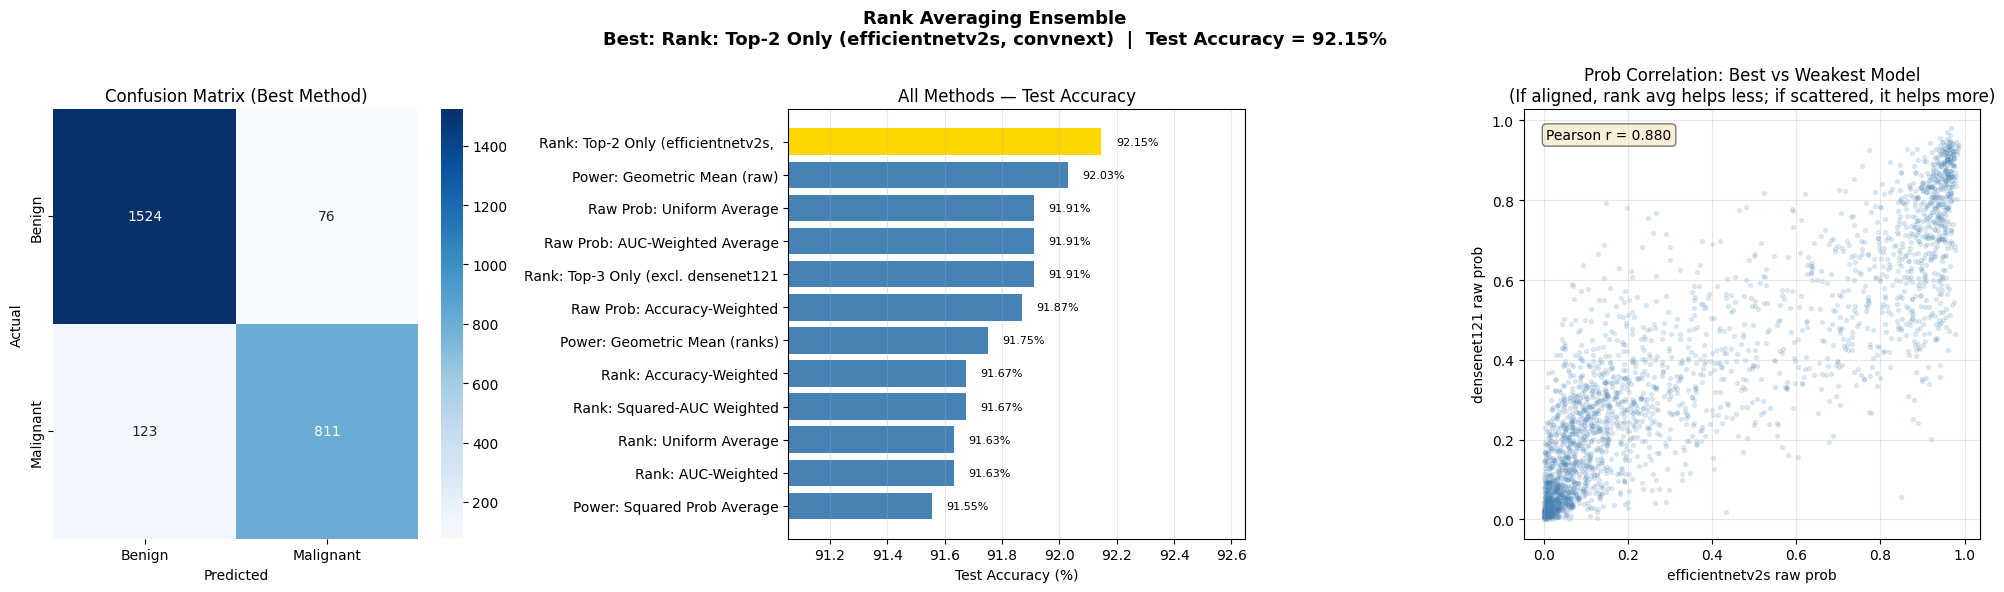

rank_averaging_results.png saved


In [11]:
# ── Cell 10: Visualization ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle(f'Rank Averaging Ensemble\n'
             f'Best: {best_name}  |  Test Accuracy = {best_r["test_acc"]*100:.2f}%',
             fontsize=13, fontweight='bold')

# 1. Confusion matrix of best method
cm = confusion_matrix(y_test, best_r['test_preds'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix (Best Method)')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# 2. Test accuracy bar chart (top 12)
top12 = sorted_results[:12]
names_s = [n[:35] for n, _ in top12]
accs = [r['test_acc'] * 100 for _, r in top12]
colors_b = ['gold'] + ['steelblue'] * (len(top12) - 1)
bars = axes[1].barh(names_s[::-1], accs[::-1], color=colors_b[::-1])
for bar, acc in zip(bars, accs[::-1]):
    axes[1].text(acc + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{acc:.2f}%', va='center', fontsize=8)
axes[1].set_xlabel('Test Accuracy (%)')
axes[1].set_title('All Methods — Test Accuracy')
axes[1].set_xlim(min(accs) - 0.5, max(accs) + 0.5)
axes[1].grid(axis='x', alpha=0.3)

# 3. Rank distribution comparison (val set, 2 models)
m1, m2 = sorted_by_auc[0], sorted_by_auc[-1]
axes[2].scatter(val_probs_dict[m1], val_probs_dict[m2], alpha=0.15, s=8, c='steelblue')
axes[2].set_xlabel(f'{m1} raw prob')
axes[2].set_ylabel(f'{m2} raw prob')
axes[2].set_title(f'Prob Correlation: Best vs Weakest Model\n'
                  f'(If aligned, rank avg helps less; if scattered, it helps more)')
axes[2].grid(alpha=0.3)
corr = np.corrcoef(val_probs_dict[m1], val_probs_dict[m2])[0, 1]
axes[2].text(0.05, 0.93, f'Pearson r = {corr:.3f}', transform=axes[2].transAxes,
             fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('/kaggle/working/rank_averaging_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('rank_averaging_results.png saved')


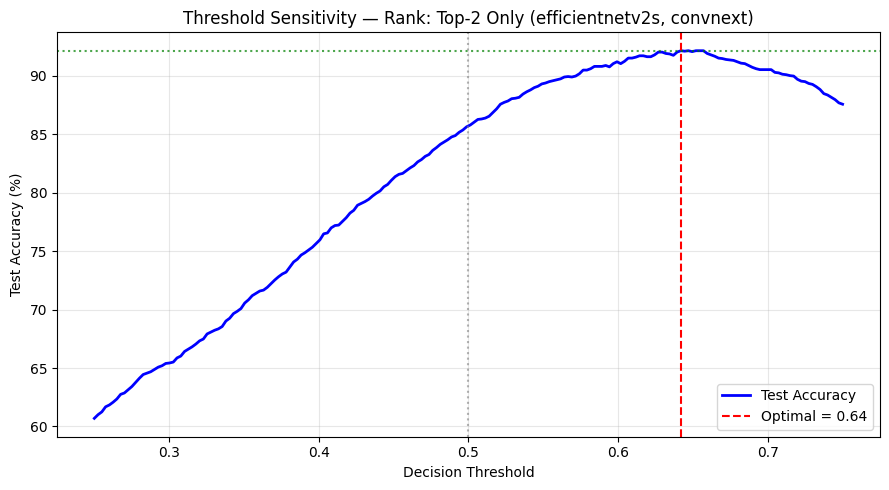

Accuracy at threshold=0.50 : 85.79%
Accuracy at threshold=0.64 : 92.15%
Gain from threshold tuning : +6.35%


In [12]:
# ── Cell 11: Threshold Sensitivity ─────────────────────────────────────────
thresholds = np.linspace(0.25, 0.75, 200)
test_accs  = [accuracy_score(y_test, (best_r['test_blend'] >= t).astype(int)) * 100
              for t in thresholds]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, test_accs, 'b-', lw=2, label='Test Accuracy')
ax.axvline(x=best_r['threshold'], color='red', ls='--', lw=1.5,
           label=f'Optimal = {best_r["threshold"]:.2f}')
ax.axhline(y=best_r['test_acc']*100, color='green', ls=':', alpha=0.7)
ax.set_xlabel('Decision Threshold'); ax.set_ylabel('Test Accuracy (%)')
ax.set_title(f'Threshold Sensitivity — {best_name}')
ax.legend(); ax.grid(alpha=0.3)
std_acc = accuracy_score(y_test, (best_r['test_blend'] >= 0.5).astype(int)) * 100
ax.axvline(x=0.5, color='gray', ls=':', alpha=0.6, label='Standard 0.5')
gain = best_r['test_acc']*100 - std_acc
plt.tight_layout()
plt.savefig('/kaggle/working/rank_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Accuracy at threshold=0.50 : {std_acc:.2f}%')
print(f'Accuracy at threshold={best_r["threshold"]:.2f} : {best_r["test_acc"]*100:.2f}%')
print(f'Gain from threshold tuning : {gain:+.2f}%')


In [13]:
# ── Cell 12: Classification Report ─────────────────────────────────────────
print(f'Classification Report — {best_name}')
print(classification_report(y_test, best_r['test_preds'],
      target_names=['Benign (0)', 'Malignant (1)'], digits=4))


Classification Report — Rank: Top-2 Only (efficientnetv2s, convnext)
               precision    recall  f1-score   support

   Benign (0)     0.9253    0.9525    0.9387      1600
Malignant (1)     0.9143    0.8683    0.8907       934

     accuracy                         0.9215      2534
    macro avg     0.9198    0.9104    0.9147      2534
 weighted avg     0.9213    0.9215    0.9210      2534



In [14]:
# ── Cell 13: Save & Submission ──────────────────────────────────────────────
np.save('/kaggle/working/rank_avg_best_test_blend.npy', best_r['test_blend'])
np.save('/kaggle/working/rank_avg_best_test_preds.npy', best_r['test_preds'])
print('Saved: rank_avg_best_test_blend.npy')
print('Saved: rank_avg_best_test_preds.npy')

INPUT_CSV_DIR = '/kaggle/working'
TEST_CSV_PATH = os.path.join(INPUT_CSV_DIR, 'binary_test.csv')

if os.path.exists(TEST_CSV_PATH):
    test_df = pd.read_csv(TEST_CSV_PATH)
    if len(test_df) == len(best_r['test_blend']):
        sub = pd.DataFrame({'image': test_df['image'], 'target': best_r['test_blend']})
        sub_path = os.path.join(NPY_DIR, 'rank_avg_submission.csv')
        sub.to_csv(sub_path, index=False)
        print(f'Submission saved -> {sub_path}')
        print(sub.head())
    else:
        print('WARNING: CSV row count mismatch')
else:
    print('Test CSV not found. Files saved as .npy')


Saved: rank_avg_best_test_blend.npy
Saved: rank_avg_best_test_preds.npy
Test CSV not found. Files saved as .npy


In [15]:
# ── Cell 14: FINAL SUMMARY ──────────────────────────────────────────────────
print()
print('#' * 65)
print('#       RANK AVERAGING ENSEMBLE -- FINAL RESULTS               #')
print('#' * 65)
print(f'#  Winning Method  : {best_name[:43]:<43} #')
print(f'#  Threshold       : {best_r["threshold"]:.2f}{" "*40} #')
print(f'#  Val  Accuracy   : {best_r["val_acc"]*100:.2f}%{" "*38} #')
print(f'#  Test Accuracy   : {best_r["test_acc"]*100:.2f}%  <-- PRIMARY METRIC{" "*19} #')
print(f'#  Test AUC        : {best_r["test_auc"]:.4f}{" "*39} #')
print('#' * 65)
print()
print('Rank variants tested:')
print('  - Uniform rank average')
print('  - AUC-weighted rank average')
print('  - Accuracy-weighted rank average')
print('  - Squared-AUC weighted rank average')
print('  - Top-2 models only (rank avg)')
print('  - Top-3 models only (rank avg)')
print('  - Geometric mean (raw probs & ranks)')
print('  - Squared prob average')
print()
print('Output files:')
print('  rank_avg_best_test_blend.npy')
print('  rank_avg_best_test_preds.npy')
print('  rank_averaging_results.png')
print('  rank_threshold_sensitivity.png')



#################################################################
#       RANK AVERAGING ENSEMBLE -- FINAL RESULTS               #
#################################################################
#  Winning Method  : Rank: Top-2 Only (efficientnetv2s, convnext #
#  Threshold       : 0.64                                         #
#  Val  Accuracy   : 92.81%                                       #
#  Test Accuracy   : 92.15%  <-- PRIMARY METRIC                    #
#  Test AUC        : 0.9710                                        #
#################################################################

Rank variants tested:
  - Uniform rank average
  - AUC-weighted rank average
  - Accuracy-weighted rank average
  - Squared-AUC weighted rank average
  - Top-2 models only (rank avg)
  - Top-3 models only (rank avg)
  - Geometric mean (raw probs & ranks)
  - Squared prob average

Output files:
  rank_avg_best_test_blend.npy
  rank_avg_best_test_preds.npy
  rank_averaging_results.png
  rank_t